# B3 Data Quality Checks

Validates the parsed COTAHIST data before using it in production.
Run after `scripts/build_b3_parquets.py` has completed.

**Sections**
1. Setup & load data
2. Cross-source price reconciliation (COTAHIST vs Yahoo; ATM IV vs IVBR/VXEWZ)
3. Coverage — strike availability at target delta
4. Spread sanity — bid/ask quality
5. Delta monotonicity
6. Put-call parity
7. IV smile shape
8. Coverage gaps (monthly)
9. Round-trip cost simulation
10. Summary report

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings

warnings.filterwarnings("ignore")

# Allow import of b3_parser from scripts/
REPO = Path("..").resolve()
sys.path.insert(0, str(REPO / "scripts"))
from b3_parser import (
    parse_cotahist,
    extract_equity_prices,
    fetch_cdi_rates,
    compute_daily_atm_iv,
    bs_price,
)

DATA_DIR = REPO / "data" / "B3"
B3_FILES = sorted(DATA_DIR.glob("COTAHIST_A*.TXT"))
print(f"COTAHIST files found: {len(B3_FILES)}")
print([f.name for f in B3_FILES])

COTAHIST files found: 17
['COTAHIST_A2010.TXT', 'COTAHIST_A2011.TXT', 'COTAHIST_A2012.TXT', 'COTAHIST_A2013.TXT', 'COTAHIST_A2014.TXT', 'COTAHIST_A2015.TXT', 'COTAHIST_A2016.TXT', 'COTAHIST_A2017.TXT', 'COTAHIST_A2018.TXT', 'COTAHIST_A2019.TXT', 'COTAHIST_A2020.TXT', 'COTAHIST_A2021.TXT', 'COTAHIST_A2022.TXT', 'COTAHIST_A2023.TXT', 'COTAHIST_A2024.TXT', 'COTAHIST_A2025.TXT', 'COTAHIST_A2026.TXT']


## 1 — Setup & load data

Load the pre-built backtest parquets (fast, ATM slice) for Section 2.
For Sections 3-9 we need the full options chain — parsed on the fly for
a representative year (change `SAMPLE_YEAR` to explore others).

In [3]:
# ── Load pre-built backtest parquets ─────────────────────────────────────────
bova_bt = pd.read_parquet(DATA_DIR / "bova11_backtest.parquet")
petr_bt = pd.read_parquet(DATA_DIR / "petr4_backtest.parquet")

print("BOVA11 backtest parquet:")
print(bova_bt.info())
print(bova_bt.describe().round(2))

print("\nPETR4 backtest parquet:")
print(petr_bt.info())
print(petr_bt.describe().round(2))

BOVA11 backtest parquet:
<class 'pandas.DataFrame'>
DatetimeIndex: 4048 entries, 2010-01-04 to 2026-04-30
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   underlying_open   4048 non-null   float64
 1   underlying_high   4048 non-null   float64
 2   underlying_low    4048 non-null   float64
 3   underlying_close  4048 non-null   float64
 4   vix_close         2512 non-null   float64
 5   risk_free_rate    4048 non-null   float64
dtypes: float64(6)
memory usage: 221.4 KB
None
       underlying_open  underlying_high  underlying_low  underlying_close  \
count          4048.00          4048.00         4048.00           4048.00   
mean             84.22            84.89           83.50             84.19   
std              31.71            31.88           31.58             31.73   
min              36.32            36.61           36.01             36.45   
25%              56.60            57.01           55.9

In [4]:
# ── Parse a sample year for detailed option-level checks ─────────────────────
# Change to any year present in DATA_DIR
SAMPLE_YEAR = 2024
SAMPLE_FILE = DATA_DIR / f"COTAHIST_A{SAMPLE_YEAR}.TXT"

cdi = fetch_cdi_rates(f"{SAMPLE_YEAR}-01-01", f"{SAMPLE_YEAR}-12-31")

print(f"Parsing BOVA11 options for {SAMPLE_YEAR}...")
eq_bova = extract_equity_prices(SAMPLE_FILE, ["BOVA11"])
opts_bova = parse_cotahist(
    SAMPLE_FILE,
    underlying_names=["BOVA", "ISHARES"],
    min_trades=1,
    min_volume=100,
    min_price=0.01,
    max_moneyness=0.30,
    min_dte=7,
    max_dte=90,
    compute_greeks_flag=True,
    risk_free_rates=cdi,
    underlying_prices=eq_bova,
    verbose=True,
)

print(f"\nParsing PETR4 options for {SAMPLE_YEAR}...")
eq_petr = extract_equity_prices(SAMPLE_FILE, ["PETR4"])
opts_petr = parse_cotahist(
    SAMPLE_FILE,
    underlying_names=["PETR"],
    min_trades=1,
    min_volume=100,
    min_price=0.01,
    max_moneyness=0.30,
    min_dte=7,
    max_dte=90,
    compute_greeks_flag=True,
    risk_free_rates=cdi,
    underlying_prices=eq_petr,
    verbose=True,
)

Parsing BOVA11 options for 2024...
  Parsing COTAHIST_A2024.TXT...
  Moneyness filter removed 3,393 deep OTM/ITM records.
  Computing IV and Greeks for 61,845 records...
  → 61,845 records  (calls: 29,801  puts: 32,044  IV ok: 49,037)

Parsing PETR4 options for 2024...
  Parsing COTAHIST_A2024.TXT...
  Moneyness filter removed 14,986 deep OTM/ITM records.
  Computing IV and Greeks for 100,354 records...
  → 100,354 records  (calls: 52,511  puts: 47,843  IV ok: 82,282)


## 2 — Cross-source price reconciliation

### 2a. Equity close: COTAHIST vs Yahoo Finance

In [7]:
import yfinance as yf

start_date = str(bova_bt.index.min().date())
end_date = str(bova_bt.index.max().date())

print(f"Fetching Yahoo data from {start_date} to {end_date}...")
yf_bova = yf.download(
    "BOVA11.SA", start=start_date, end=end_date, auto_adjust=False, progress=False
)["Close"]
yf_petr = yf.download(
    "PETR4.SA", start=start_date, end=end_date, auto_adjust=False, progress=False
)["Close"]

# Align to COTAHIST dates
yf_bova.index = pd.to_datetime(yf_bova.index).tz_localize(None)
yf_petr.index = pd.to_datetime(yf_petr.index).tz_localize(None)


def reconcile(cot_close, yf_close, label):
    merged = pd.DataFrame({"cotahist": cot_close, "yahoo": yf_close}).dropna()
    merged["diff_pct"] = (
        (merged["cotahist"] - merged["yahoo"]).abs() / merged["yahoo"] * 100
    )
    flagged = merged[merged["diff_pct"] > 0.5]
    print(f"\n{label}")
    print(f"  Aligned dates : {len(merged):,}")
    print(f'  Max diff      : {merged["diff_pct"].max():.3f}%')
    print(f'  Median diff   : {merged["diff_pct"].median():.4f}%')
    print(f"  Flagged (>0.5%): {len(flagged):,}")
    if not flagged.empty:
        print(flagged.head(10).to_string())
    return merged


rec_bova = reconcile(bova_bt["underlying_close"].squeeze(), yf_bova.squeeze(), "BOVA11")
rec_petr = reconcile(petr_bt["underlying_close"].squeeze(), yf_petr.squeeze(), "PETR4")

Fetching Yahoo data from 2010-01-04 to 2026-04-30...

BOVA11
  Aligned dates : 4,026
  Max diff      : 0.779%
  Median diff   : 0.0000%
  Flagged (>0.5%): 1
            cotahist       yahoo  diff_pct
2020-12-30    114.65  115.550003  0.778886

PETR4
  Aligned dates : 4,045
  Max diff      : 20.638%
  Median diff   : 0.0000%
  Flagged (>0.5%): 133
            cotahist      yahoo  diff_pct
2010-05-28     28.20  27.809999  1.402375
2010-09-09     27.60  27.410000  0.693178
2011-02-09     26.18  26.879999  2.604164
2011-02-10     26.27  26.879999  2.269342
2011-02-24     28.37  28.709999  1.184253
2011-03-09     28.55  29.080000  1.822558
2011-03-22     28.33  28.129999  0.710988
2011-03-23     28.62  28.129999  1.741916
2011-03-25     28.64  28.430000  0.738655
2011-04-01     28.74  28.370001  1.304192


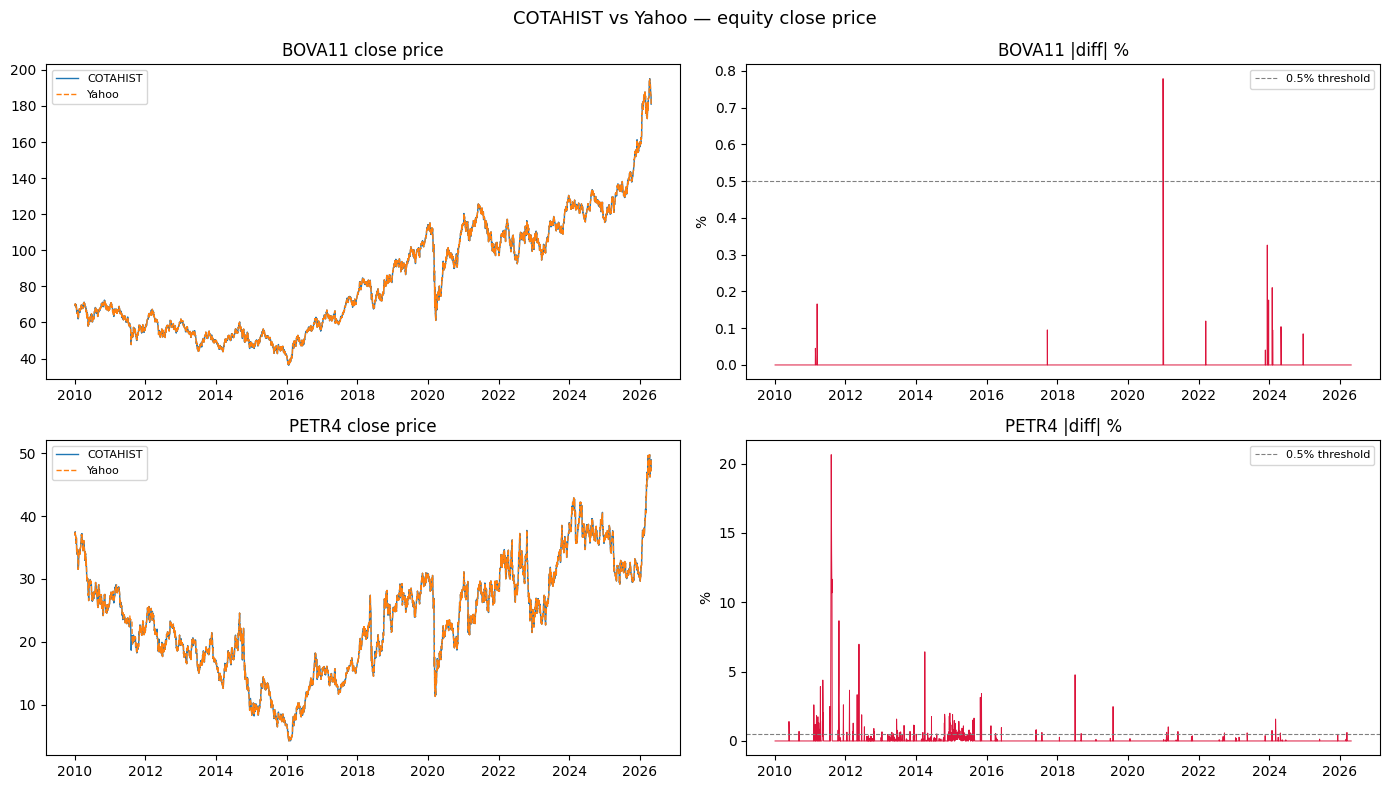

Saved → data/B3/qa_equity_price_reconciliation.png


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle("COTAHIST vs Yahoo — equity close price", fontsize=13)

for i, (rec, label) in enumerate([(rec_bova, "BOVA11"), (rec_petr, "PETR4")]):
    ax = axes[i, 0]
    ax.plot(rec.index, rec["cotahist"], label="COTAHIST", lw=1)
    ax.plot(rec.index, rec["yahoo"], label="Yahoo", lw=1, ls="--")
    ax.set_title(f"{label} close price")
    ax.legend(fontsize=8)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    ax2 = axes[i, 1]
    ax2.plot(rec.index, rec["diff_pct"], lw=0.7, color="crimson")
    ax2.axhline(0.5, ls="--", color="gray", lw=0.8, label="0.5% threshold")
    ax2.set_title(f"{label} |diff| %")
    ax2.set_ylabel("%")
    ax2.legend(fontsize=8)
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.savefig(DATA_DIR / "qa_equity_price_reconciliation.png", dpi=150)
plt.show()
print("Saved → data/B3/qa_equity_price_reconciliation.png")

### 2b. ATM IV: synthetic (COTAHIST) vs VXEWZ (Yahoo)

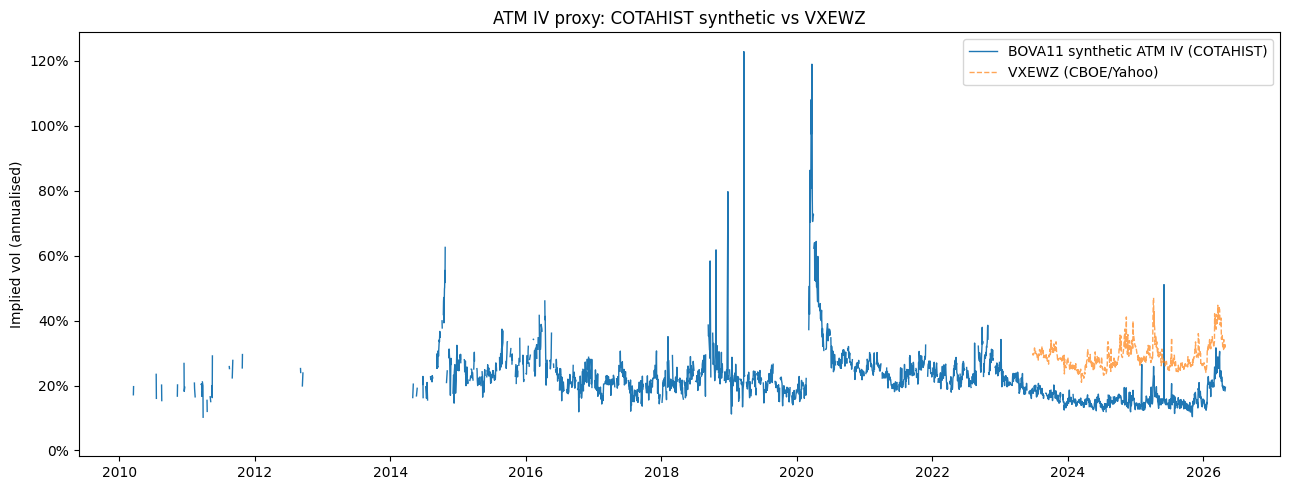

Saved → data/B3/qa_iv_vs_vxewz.png
Correlation (COTAHIST ATM IV vs VXEWZ): 0.691


In [10]:
# VXEWZ — CBOE vol index for EWZ (US-listed Brazil ETF), goes back ~2011
# Noisy proxy but useful for directional sanity check
vxewz_raw = yf.download(
    "^VXEWZ", start=start_date, end=end_date, auto_adjust=False, progress=False
)["Close"]
vxewz = pd.Series(
    vxewz_raw.values.squeeze() / 100.0,
    index=pd.to_datetime(vxewz_raw.index).tz_localize(None),
    name="vxewz",
)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(
    bova_bt.index,
    bova_bt["vix_close"],
    label="BOVA11 synthetic ATM IV (COTAHIST)",
    lw=1,
)
ax.plot(vxewz.index, vxewz, label="VXEWZ (CBOE/Yahoo)", lw=1, ls="--", alpha=0.7)
ax.set_title("ATM IV proxy: COTAHIST synthetic vs VXEWZ")
ax.set_ylabel("Implied vol (annualised)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend()
plt.tight_layout()
plt.savefig(DATA_DIR / "qa_iv_vs_vxewz.png", dpi=150)
plt.show()
print("Saved → data/B3/qa_iv_vs_vxewz.png")

# Correlation
merged_iv = pd.DataFrame({"cotahist": bova_bt["vix_close"], "vxewz": vxewz}).dropna()
corr = merged_iv.corr().iloc[0, 1]
print(f"Correlation (COTAHIST ATM IV vs VXEWZ): {corr:.3f}")

## 3 — Coverage at target delta

For each trading day, verify that at least one call and one put with
|delta| near 0.16 exists in the 30–45 DTE window.

In [11]:
TARGET_DELTA = 0.16
DELTA_TOL = 0.06  # accept 0.10–0.22 as "near 16Δ"
DTE_MIN, DTE_MAX = 30, 45


def coverage_check(opts, label):
    window = opts[
        (opts["dte"] >= DTE_MIN) & (opts["dte"] <= DTE_MAX) & opts["delta"].notna()
    ]
    calls = window[window["option_type"] == "call"]
    puts = window[window["option_type"] == "put"]

    near_call = calls[
        calls["delta"].between(TARGET_DELTA - DELTA_TOL, TARGET_DELTA + DELTA_TOL)
    ]
    near_put = puts[
        puts["delta"].abs().between(TARGET_DELTA - DELTA_TOL, TARGET_DELTA + DELTA_TOL)
    ]

    all_dates = set(window["date"].dt.date.unique())
    call_covered = set(near_call["date"].dt.date.unique())
    put_covered = set(near_put["date"].dt.date.unique())
    both_covered = call_covered & put_covered
    missing = all_dates - both_covered

    print(f"\n{label}")
    print(f"  Trading days in window  : {len(all_dates):,}")
    print(
        f"  Days with call near 16Δ : {len(call_covered):,}  ({len(call_covered)/len(all_dates):.1%})"
    )
    print(
        f"  Days with put near 16Δ  : {len(put_covered):,}  ({len(put_covered)/len(all_dates):.1%})"
    )
    print(
        f"  Days with both          : {len(both_covered):,}  ({len(both_covered)/len(all_dates):.1%})"
    )
    if missing:
        print(f"  Missing days (sample)   : {sorted(missing)[:10]}")


coverage_check(opts_bova, f"BOVA11 {SAMPLE_YEAR}")
coverage_check(opts_petr, f"PETR4  {SAMPLE_YEAR}")


BOVA11 2024
  Trading days in window  : 239
  Days with call near 16Δ : 170  (71.1%)
  Days with put near 16Δ  : 179  (74.9%)
  Days with both          : 154  (64.4%)
  Missing days (sample)   : [datetime.date(2024, 1, 29), datetime.date(2024, 2, 16), datetime.date(2024, 2, 19), datetime.date(2024, 2, 20), datetime.date(2024, 2, 22), datetime.date(2024, 2, 23), datetime.date(2024, 2, 29), datetime.date(2024, 3, 1), datetime.date(2024, 3, 21), datetime.date(2024, 3, 22)]

PETR4  2024
  Trading days in window  : 235
  Days with call near 16Δ : 168  (71.5%)
  Days with put near 16Δ  : 171  (72.8%)
  Days with both          : 150  (63.8%)
  Missing days (sample)   : [datetime.date(2024, 1, 29), datetime.date(2024, 2, 16), datetime.date(2024, 2, 19), datetime.date(2024, 2, 21), datetime.date(2024, 2, 22), datetime.date(2024, 2, 27), datetime.date(2024, 2, 28), datetime.date(2024, 2, 29), datetime.date(2024, 3, 1), datetime.date(2024, 3, 4)]


## 4 — Spread sanity


BOVA11 2024
  Records with bid/ask    : 35,024 / 61,845  (56.6%)
  Inverted (ask < bid)    : 26
  Wide (spread > 100%)    : 5,269  (15.0%)
  Zero mid_price          : 0
  Median spread %         : 30.7%
  95th pct spread %       : 170.4%

PETR4  2024
  Records with bid/ask    : 52,002 / 100,354  (51.8%)
  Inverted (ask < bid)    : 50
  Wide (spread > 100%)    : 9,214  (17.7%)
  Zero mid_price          : 0
  Median spread %         : 39.5%
  95th pct spread %       : 177.3%


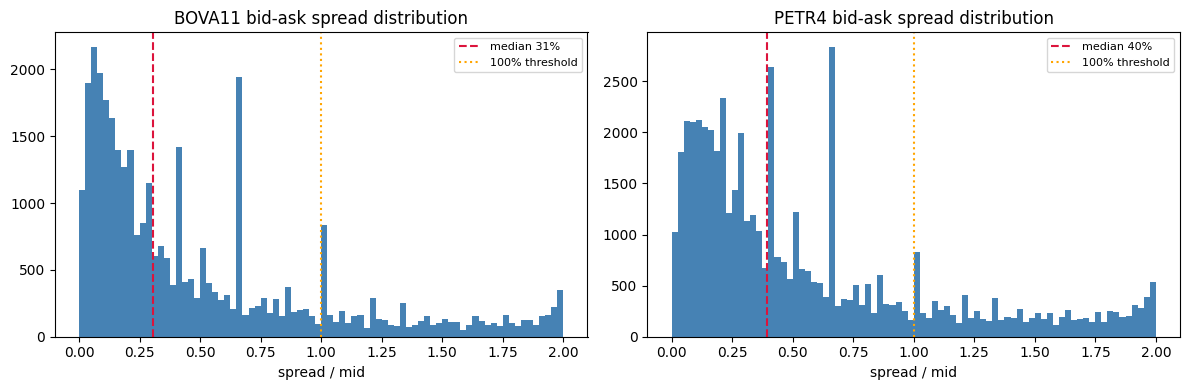

In [12]:
def spread_sanity(opts, label):
    valid = opts[
        opts["bid"].notna()
        & opts["ask"].notna()
        & (opts["bid"] > 0)
        & (opts["ask"] > 0)
    ]
    inverted = valid[valid["ask"] < valid["bid"]]
    wide = valid[valid["spread_pct"] > 1.0]  # spread > 100% of mid
    zero_mid = valid[valid["mid_price"] <= 0]

    print(f"\n{label}")
    print(
        f"  Records with bid/ask    : {len(valid):,} / {len(opts):,}  ({len(valid)/len(opts):.1%})"
    )
    print(f"  Inverted (ask < bid)    : {len(inverted):,}")
    print(f"  Wide (spread > 100%)    : {len(wide):,}  ({len(wide)/len(valid):.1%})")
    print(f"  Zero mid_price          : {len(zero_mid):,}")
    print(f'  Median spread %         : {valid["spread_pct"].median():.1%}')
    print(f'  95th pct spread %       : {valid["spread_pct"].quantile(0.95):.1%}')


spread_sanity(opts_bova, f"BOVA11 {SAMPLE_YEAR}")
spread_sanity(opts_petr, f"PETR4  {SAMPLE_YEAR}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, opts, label in zip(axes, [opts_bova, opts_petr], ["BOVA11", "PETR4"]):
    sp = opts["spread_pct"].dropna().clip(0, 2)
    ax.hist(sp, bins=80, color="steelblue", edgecolor="none")
    ax.axvline(sp.median(), color="crimson", ls="--", label=f"median {sp.median():.0%}")
    ax.axvline(1.0, color="orange", ls=":", label="100% threshold")
    ax.set_title(f"{label} bid-ask spread distribution")
    ax.set_xlabel("spread / mid")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(DATA_DIR / "qa_spread_distribution.png", dpi=150)
plt.show()

## 5 — Delta monotonicity

Within (date, expiration, type), strike↑ should → delta↓ for calls and
delta↑ (less negative) for puts. Non-monotonic rows indicate stale quotes.

In [13]:
def delta_monotonicity(opts, label):
    has_delta = opts[opts["delta"].notna()].copy()
    violations = 0
    total_chains = 0

    for (date, exp, otype), grp in has_delta.groupby(["date", "expiry", "option_type"]):
        grp = grp.sort_values("strike")
        if len(grp) < 2:
            continue
        total_chains += 1
        deltas = grp["delta"].values
        if otype == "call":
            # call delta should decrease as strike increases
            if not (np.diff(deltas) <= 0.01).all():  # allow tiny numerical noise
                violations += 1
        else:
            # put delta (negative) should increase (become less negative) as strike increases
            if not (np.diff(deltas) >= -0.01).all():
                violations += 1

    pct = violations / total_chains * 100 if total_chains else 0
    print(
        f"{label}: {violations:,} / {total_chains:,} chains with monotonicity violations ({pct:.2f}%)"
    )


delta_monotonicity(opts_bova, f"BOVA11 {SAMPLE_YEAR}")
delta_monotonicity(opts_petr, f"PETR4  {SAMPLE_YEAR}")

BOVA11 2024: 2,196 / 2,806 chains with monotonicity violations (78.26%)
PETR4  2024: 2,266 / 2,779 chains with monotonicity violations (81.54%)


## 6 — Put-call parity

For ATM options: C - P ≈ S - K·e^(-rT)
Large residuals indicate mismatch between calls and puts on the same expiry.

In [14]:
def pcp_check(opts, label, atm_moneyness=0.03):
    has_price = opts[opts["underlying_price"].notna()].copy()
    has_price["moneyness"] = (
        has_price["underlying_price"] - has_price["strike"]
    ).abs() / has_price["underlying_price"]
    atm = has_price[has_price["moneyness"] <= atm_moneyness]

    calls = atm[atm["option_type"] == "call"].set_index(["date", "expiry", "strike"])[
        ["mid_price", "underlying_price", "risk_free_rate", "dte"]
    ]
    puts = atm[atm["option_type"] == "put"].set_index(["date", "expiry", "strike"])[
        ["mid_price"]
    ]

    paired = calls.join(puts, rsuffix="_put").dropna()
    paired.columns = ["call_mid", "S", "r", "dte", "put_mid"]

    T = paired["dte"] / 365.0
    K = paired.index.get_level_values("strike")
    theoretical = paired["S"] - K * np.exp(-paired["r"] * T)
    actual = paired["call_mid"] - paired["put_mid"]
    residual = (actual - theoretical).abs() / paired["S"] * 100

    print(f"\n{label}  (ATM ±{atm_moneyness:.0%}, {len(paired):,} pairs)")
    print(f"  Median |residual| / S : {residual.median():.3f}%")
    print(f"  95th pct              : {residual.quantile(0.95):.3f}%")
    print(f"  Max                   : {residual.max():.3f}%")
    large = residual[residual > 2.0]
    print(f"  > 2% threshold        : {len(large):,}  ({len(large)/len(residual):.1%})")
    return residual


res_bova = pcp_check(opts_bova, f"BOVA11 {SAMPLE_YEAR}")
res_petr = pcp_check(opts_petr, f"PETR4  {SAMPLE_YEAR}")


BOVA11 2024  (ATM ±3%, 7,210 pairs)
  Median |residual| / S : 0.162%
  95th pct              : 0.988%
  Max                   : 99.225%
  > 2% threshold        : 81  (1.1%)

PETR4  2024  (ATM ±3%, 9,088 pairs)
  Median |residual| / S : 0.380%
  95th pct              : 4.698%
  Max                   : 23.677%
  > 2% threshold        : 1,295  (14.2%)


## 7 — IV smile shape

Plot IV vs strike for a few representative (date, expiration) slices.
Should show a smile/smirk (puts bid up, calls near ATM or slightly lower).

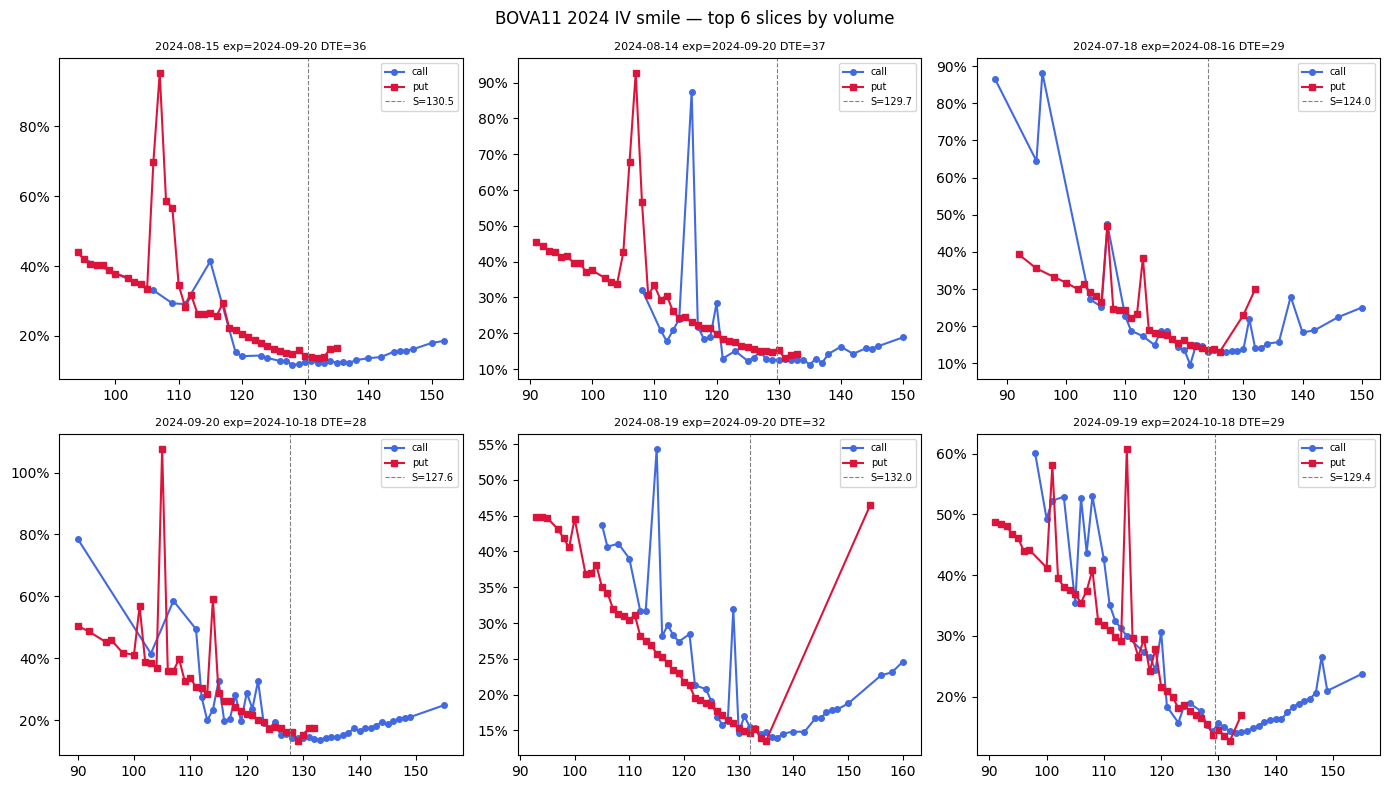

Saved → /Users/oliversteiner/Documents/code/options-backtest/data/B3/qa_iv_smile_bova11_2024.png


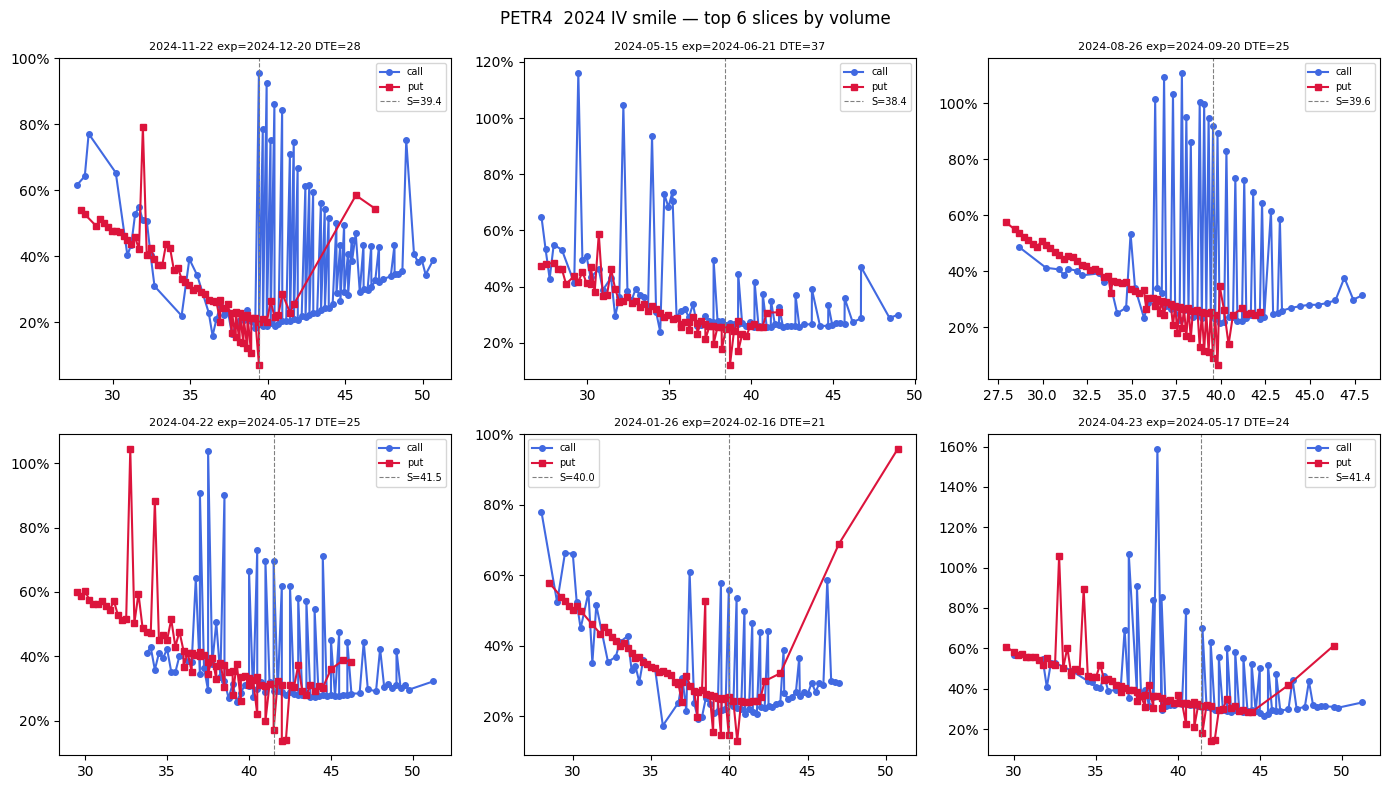

Saved → /Users/oliversteiner/Documents/code/options-backtest/data/B3/qa_iv_smile_petr4__2024.png


In [15]:
def plot_iv_smile(opts, label, n_slices=6):
    has_iv = opts[opts["iv"].notna() & (opts["dte"] >= 20) & (opts["dte"] <= 45)]
    # Pick the n most-liquid (date, expiry) pairs by total volume
    top = (
        has_iv.groupby(["date", "expiry"])["volume_brl"].sum().nlargest(n_slices).index
    )

    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    fig.suptitle(f"{label} IV smile — top {n_slices} slices by volume", fontsize=12)

    for ax, (date, exp) in zip(axes.flat, top):
        sl = has_iv[(has_iv["date"] == date) & (has_iv["expiry"] == exp)]
        calls = sl[sl["option_type"] == "call"].sort_values("strike")
        puts = sl[sl["option_type"] == "put"].sort_values("strike")
        ax.plot(
            calls["strike"], calls["iv"], "o-", ms=4, label="call", color="royalblue"
        )
        ax.plot(puts["strike"], puts["iv"], "s-", ms=4, label="put", color="crimson")
        s0 = sl["underlying_price"].iloc[0]
        ax.axvline(s0, ls="--", lw=0.8, color="gray", label=f"S={s0:.1f}")
        dte_val = sl["dte"].iloc[0]
        ax.set_title(f"{date.date()} exp={exp.date()} DTE={dte_val}", fontsize=8)
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
        ax.legend(fontsize=7)

    plt.tight_layout()
    out = DATA_DIR / f'qa_iv_smile_{label.lower().replace(" ", "_")}.png'
    plt.savefig(out, dpi=150)
    plt.show()
    print(f"Saved → {out}")


plot_iv_smile(opts_bova, f"BOVA11 {SAMPLE_YEAR}")
plot_iv_smile(opts_petr, f"PETR4  {SAMPLE_YEAR}")

## 8 — Coverage gaps (monthly)

List every (year, month) where no valid 16Δ strangle entry was possible
across all parsed years.

In [16]:
from b3_parser import extract_equity_prices, fetch_cdi_rates, parse_cotahist


def find_coverage_gaps(underlying_name_filter, equity_ticker, label):
    """Parse all COTAHIST files and report months with no 16Δ strangle."""
    print(f"\nScanning coverage gaps for {label}...")
    valid_months = set()
    all_months = set()

    for fp in B3_FILES:
        year = int(fp.stem.replace("COTAHIST_A", ""))
        cdi = fetch_cdi_rates(f"{year}-01-01", f"{year}-12-31")
        eq = extract_equity_prices(fp, [equity_ticker])
        opts = parse_cotahist(
            fp,
            underlying_names=underlying_name_filter,
            min_trades=1,
            min_volume=100,
            min_price=0.01,
            max_moneyness=0.30,
            min_dte=30,
            max_dte=45,
            compute_greeks_flag=True,
            risk_free_rates=cdi,
            underlying_prices=eq,
            verbose=False,
        )
        if opts.empty:
            continue
        has_delta = opts[opts["delta"].notna()]
        near16 = has_delta[has_delta["delta"].abs().between(0.10, 0.22)]
        for dt in opts["date"].dt.to_period("M").unique():
            all_months.add(str(dt))
        for dt in near16["date"].dt.to_period("M").unique():
            valid_months.add(str(dt))

    gaps = sorted(all_months - valid_months)
    print(f"  Total months  : {len(all_months)}")
    print(f"  Valid months  : {len(valid_months)}")
    print(f"  Gap months    : {len(gaps)}")
    if gaps:
        print(f"  Gaps          : {gaps}")
    return gaps


gaps_bova = find_coverage_gaps(["BOVA", "ISHARES"], "BOVA11", "BOVA11")
gaps_petr = find_coverage_gaps(["PETR"], "PETR4", "PETR4")


Scanning coverage gaps for BOVA11...
  Total months  : 191
  Valid months  : 160
  Gap months    : 31
  Gaps          : ['2010-01', '2010-02', '2010-03', '2010-04', '2010-05', '2010-06', '2010-07', '2010-08', '2010-10', '2010-12', '2011-01', '2011-02', '2011-03', '2011-04', '2011-07', '2011-09', '2012-02', '2012-03', '2012-07', '2012-08', '2013-02', '2013-03', '2013-04', '2013-05', '2013-08', '2013-10', '2014-01', '2014-02', '2014-03', '2014-04', '2014-07']

Scanning coverage gaps for PETR4...


SGSError: Download error: code = 12

## 9 — Round-trip cost simulation

For each month in the sample year, simulate entering a 16Δ strangle at
the bid (entry) and exiting at the ask (worst case). Compare to synthetic
mid round-trip.

In [17]:
def round_trip_sim(opts, label):
    TARGET_DELTA = 0.16
    DELTA_TOL = 0.06

    window = opts[
        (opts["dte"] >= 30)
        & (opts["dte"] <= 45)
        & opts["delta"].notna()
        & opts["bid"].notna()
        & opts["ask"].notna()
        & (opts["bid"] > 0)
        & (opts["ask"] > 0)
    ]

    results = []
    for (date, exp), grp in window.groupby(["date", "expiry"]):
        calls = grp[
            (grp["option_type"] == "call")
            & grp["delta"].between(TARGET_DELTA - DELTA_TOL, TARGET_DELTA + DELTA_TOL)
        ]
        puts = grp[
            (grp["option_type"] == "put")
            & grp["delta"]
            .abs()
            .between(TARGET_DELTA - DELTA_TOL, TARGET_DELTA + DELTA_TOL)
        ]
        if calls.empty or puts.empty:
            continue
        c = calls.iloc[0]
        p = puts.iloc[0]
        entry_credit = (c["bid"] + p["bid"]) * 100  # sell at bid, 100 multiplier
        exit_cost = (c["ask"] + p["ask"]) * 100  # buy back at ask
        mid_credit = (c["mid_price"] + p["mid_price"]) * 100
        results.append(
            {
                "date": date,
                "expiry": exp,
                "entry_credit": entry_credit,
                "exit_cost": exit_cost,
                "round_trip_pnl": entry_credit - exit_cost,
                "mid_credit": mid_credit,
                "spread_cost": exit_cost - entry_credit,  # friction (positive = loss)
            }
        )

    if not results:
        print(f"{label}: no valid pairs found")
        return pd.DataFrame()

    df = pd.DataFrame(results)
    print(f"\n{label}  ({len(df)} months simulated)")
    print(f'  Median entry credit  : R${df["entry_credit"].median():,.0f}')
    print(f'  Median exit cost     : R${df["exit_cost"].median():,.0f}')
    print(f'  Median spread cost   : R${df["spread_cost"].median():,.0f}')
    print(f'  Median mid credit    : R${df["mid_credit"].median():,.0f}')
    print(
        f'  Spread as % of mid   : {(df["spread_cost"] / df["mid_credit"]).median():.1%}'
    )
    return df


rt_bova = round_trip_sim(opts_bova, f"BOVA11 {SAMPLE_YEAR}")
rt_petr = round_trip_sim(opts_petr, f"PETR4  {SAMPLE_YEAR}")


BOVA11 2024  (141 months simulated)
  Median entry credit  : R$78
  Median exit cost     : R$159
  Median spread cost   : R$77
  Median mid credit    : R$122
  Spread as % of mid   : 66.7%

PETR4  2024  (141 months simulated)
  Median entry credit  : R$37
  Median exit cost     : R$100
  Median spread cost   : R$64
  Median mid credit    : R$69
  Spread as % of mid   : 90.3%


## 10 — Summary report

In [18]:
print("=" * 65)
print("B3 DATA QUALITY SUMMARY")
print("=" * 65)

for bt, label in [(bova_bt, "BOVA11"), (petr_bt, "PETR4")]:
    years = (bt.index.max() - bt.index.min()).days / 365.25
    iv_cov = bt["vix_close"].notna().mean()
    rfr_cov = bt["risk_free_rate"].notna().mean()
    print(f"\n{label}")
    print(f"  Trading days   : {len(bt):,}  ({years:.1f} years)")
    print(f"  Date range     : {bt.index.min().date()} → {bt.index.max().date()}")
    print(f"  ATM IV coverage: {iv_cov:.1%}")
    print(f"  CDI coverage   : {rfr_cov:.1%}")
    print(
        f'  Close range    : {bt["underlying_close"].min():.2f} → {bt["underlying_close"].max():.2f}'
    )
    print(
        f'  IV range       : {bt["vix_close"].min():.1%} → {bt["vix_close"].max():.1%}'
    )
    print(
        f'  CDI range      : {bt["risk_free_rate"].min():.2%} → {bt["risk_free_rate"].max():.2%}'
    )

print("\n" + "=" * 65)
print(f"Sample year: {SAMPLE_YEAR}")
for opts, label in [(opts_bova, "BOVA11"), (opts_petr, "PETR4")]:
    print(
        f"  {label}: {len(opts):,} option records  "
        f'(IV ok: {opts["iv"].notna().mean():.1%}  '
        f'median spread: {opts["spread_pct"].median():.1%})'
    )
print("=" * 65)

B3 DATA QUALITY SUMMARY

BOVA11
  Trading days   : 4,048  (16.3 years)
  Date range     : 2010-01-04 → 2026-04-30
  ATM IV coverage: 62.1%
  CDI coverage   : 100.0%
  Close range    : 36.45 → 195.16
  IV range       : 4.2% → 122.8%
  CDI range      : 1.90% → 14.90%

PETR4
  Trading days   : 4,048  (16.3 years)
  Date range     : 2010-01-04 → 2026-04-30
  ATM IV coverage: 85.8%
  CDI coverage   : 100.0%
  Close range    : 4.20 → 49.78
  IV range       : 16.9% → 155.0%
  CDI range      : 1.90% → 14.90%

Sample year: 2024
  BOVA11: 61,845 option records  (IV ok: 79.3%  median spread: 30.7%)
  PETR4: 100,354 option records  (IV ok: 82.0%  median spread: 39.5%)
